# Đề tài 01 · Telco Customer Churn

Notebook bằng chứng thực nghiệm, không phải báo cáo nộp cuối. Tất cả đầu ra được thực thi từ dữ liệu/artifact thật. Không tuning lại theo test. Có hỗ trợ OpenAI Codex; nhóm cần đọc, sửa và tự kiểm chứng.

## 1. Bài toán và nguồn

Phân loại Churn: Yes=1, No=0. Dữ liệu mẫu IBM của công ty hư cấu. Câu hỏi: mức mất cân bằng; các yếu tố liên quan; mức cải thiện so với baseline; đánh đổi precision/recall. Nguồn và hash ở preparation/provenance.json. Snapshot không chứng minh dự báo trước một khoảng thời gian.

In [1]:
from pathlib import Path
import sys
root=Path.cwd()
if root.name=='notebooks': root=root.parent
sys.path.insert(0,str(root))
import pandas as pd
from IPython.display import display,Image,Markdown
from src.config import ROOT,PREP_DIR,EDA_DIR,RUN_DIR,FEATURES,NUMERIC
from src.records import read_json
from src.data import load_partition
from src.inference import load_bundle
print('Python:',sys.executable)
profile=read_json(PREP_DIR/'data_profile.json')
display(pd.DataFrame({'Giá trị':[profile['rows'],profile['columns'],profile['unique_ids'],profile['missing_blank']['TotalCharges']]},index=['Dòng','Cột','ID duy nhất','TotalCharges thiếu']))

Python: C:\Users\Asus\Desktop\TRITUENHANTAO\DU_AN_TELCO_CHURN\.venv_verify\Scripts\python.exe


,Giá trị
Dòng,7043
Cột,21
ID duy nhất,7043
TotalCharges thiếu,11


## 2. Chia tập và tiền xử lý

4.225 train / 1.409 validation / 1.409 test, stratify seed 42. Normalizer không học thống kê → ColumnTransformer → model. Median/scaler/one-hot fit bên trong từng fold. Giữ các danh mục không dùng dịch vụ; ID và target không làm đặc trưng.

In [2]:
train=load_partition('train')
print('Train:',train.shape)
display(train.head())
pipeline,metadata=load_bundle()
display(pipeline)
print('Median chỉ học từ train:',pipeline['preprocess'].named_transformers_['numeric']['imputer'].statistics_)

Train: (4225, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,8499-BRXTD,Male,0,No,No,18,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.1,401.85,No
1,4060-LDNLU,Male,0,No,No,7,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,No,Electronic check,96.2,639.7,No
2,1428-IEDPR,Male,0,No,No,52,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Electronic check,109.3,5731.4,No
3,2796-NNUFI,Female,0,Yes,Yes,46,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Mailed check,19.95,927.1,No
4,2474-BRUCM,Male,1,Yes,No,40,Yes,Yes,Fiber optic,Yes,...,No,No,Yes,Yes,Month-to-month,No,Electronic check,101.85,4086.3,Yes


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('normalize', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0",list,"['tenure', 'Mo...es', 'To...es', 'gender', ...]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
Name,Type,Value
feature_names_in_,list,"['tenure', 'Mo...es', 'To...es', 'gender', ...]"
n_features_in_,int,19


Median chỉ học từ train: [  29.    70.4 1385.3]


## 3. EDA chỉ trên train

Tám hình có CSV nguồn; không dùng biểu đồ test để quyết định mô hình.

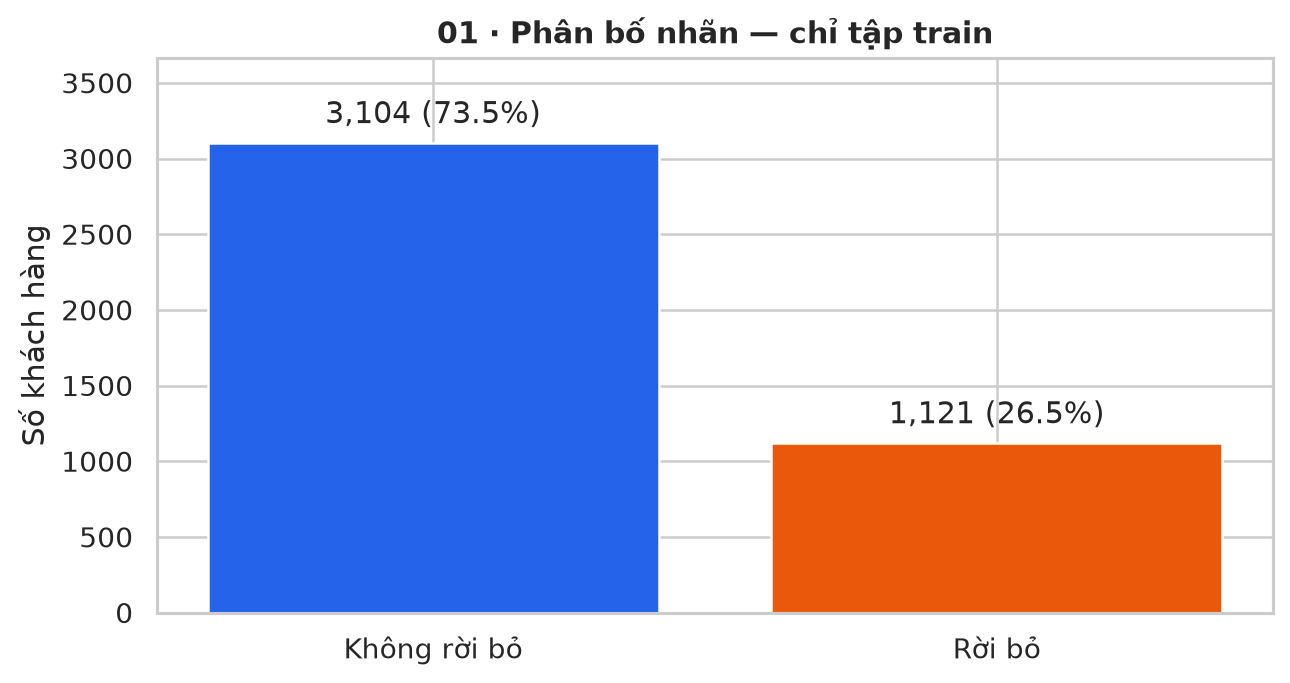

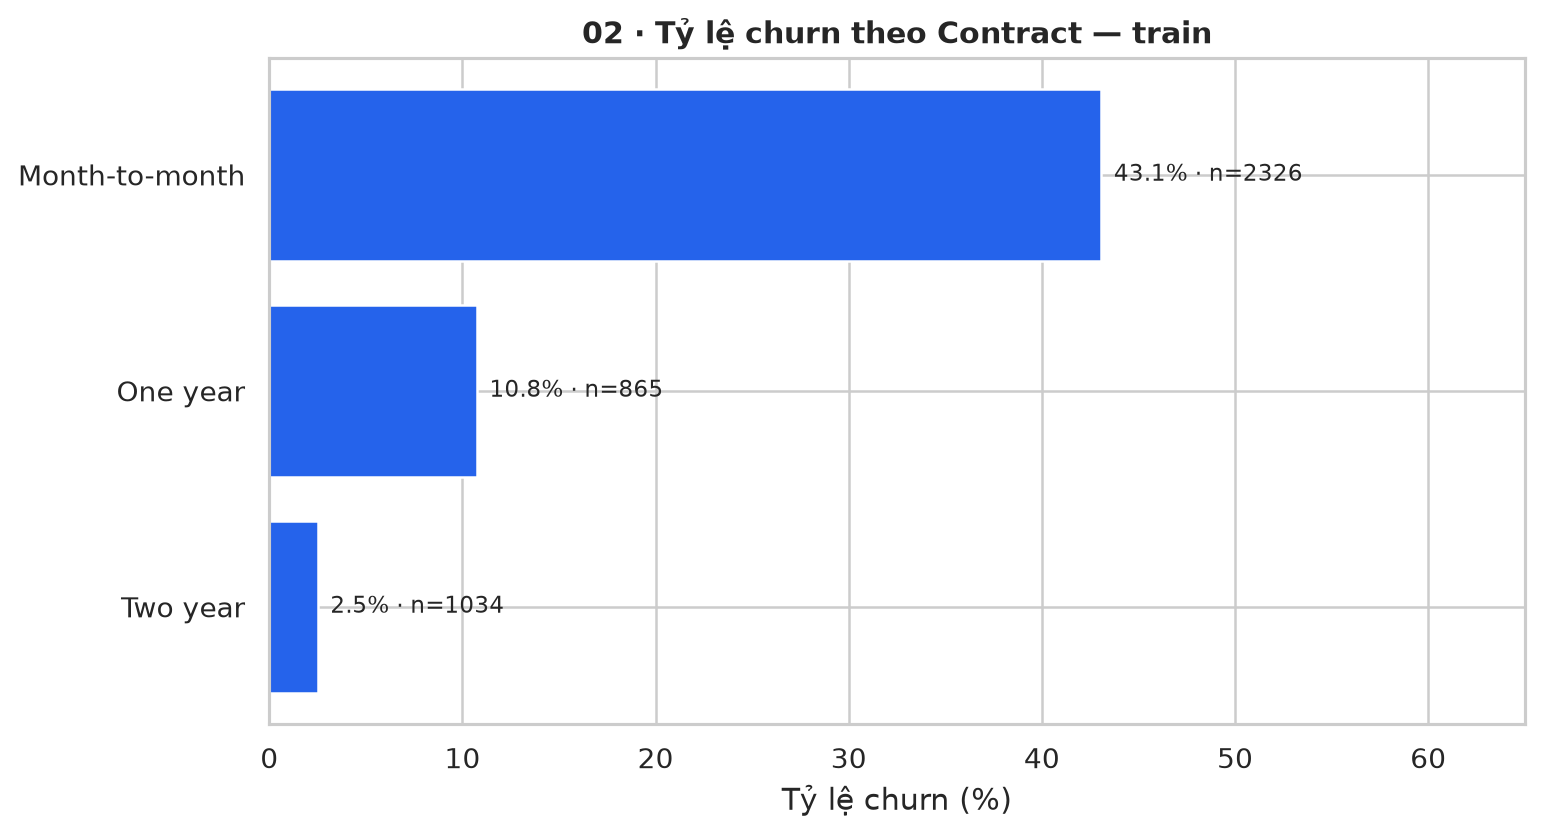

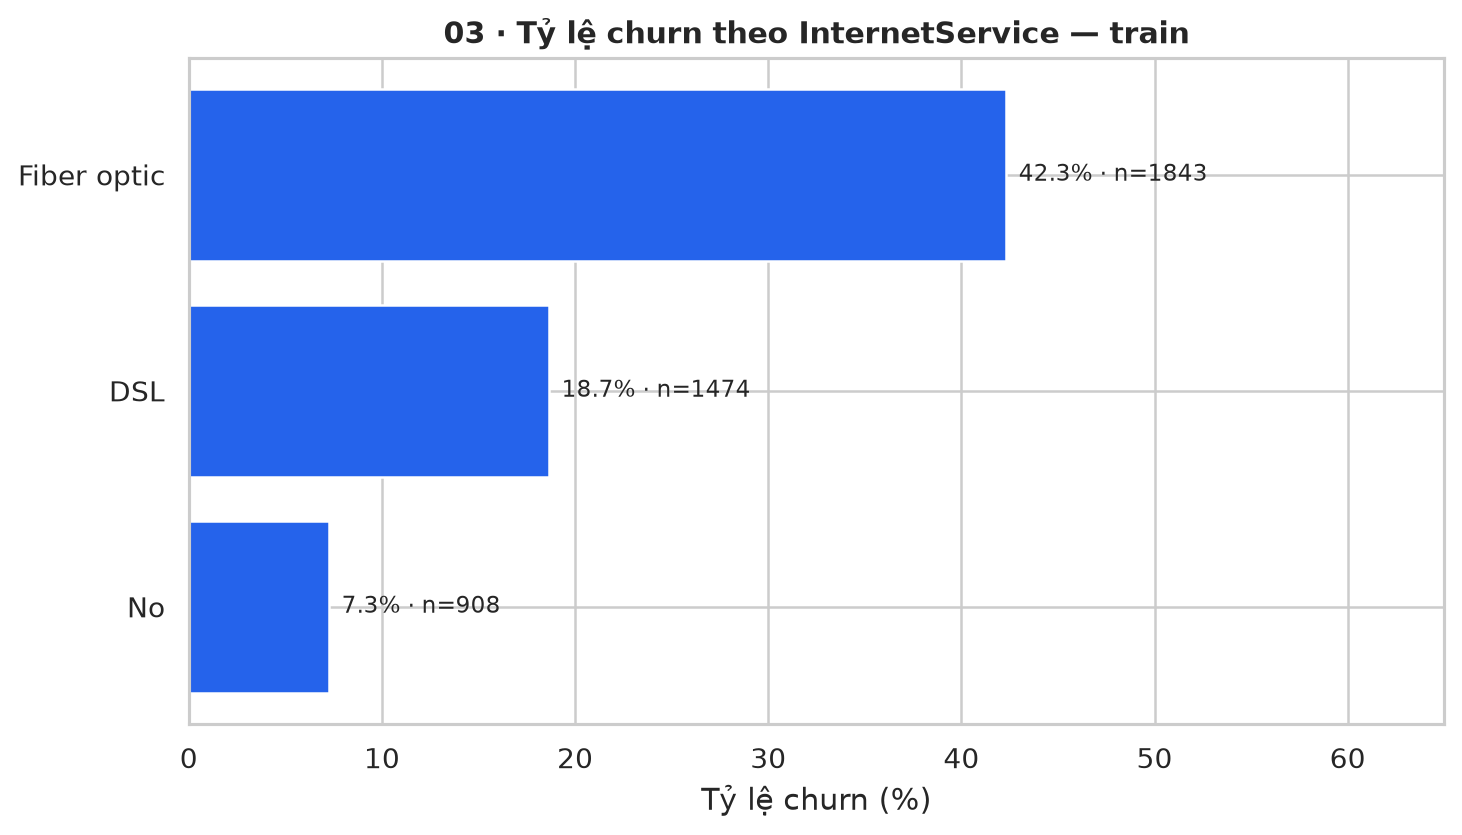

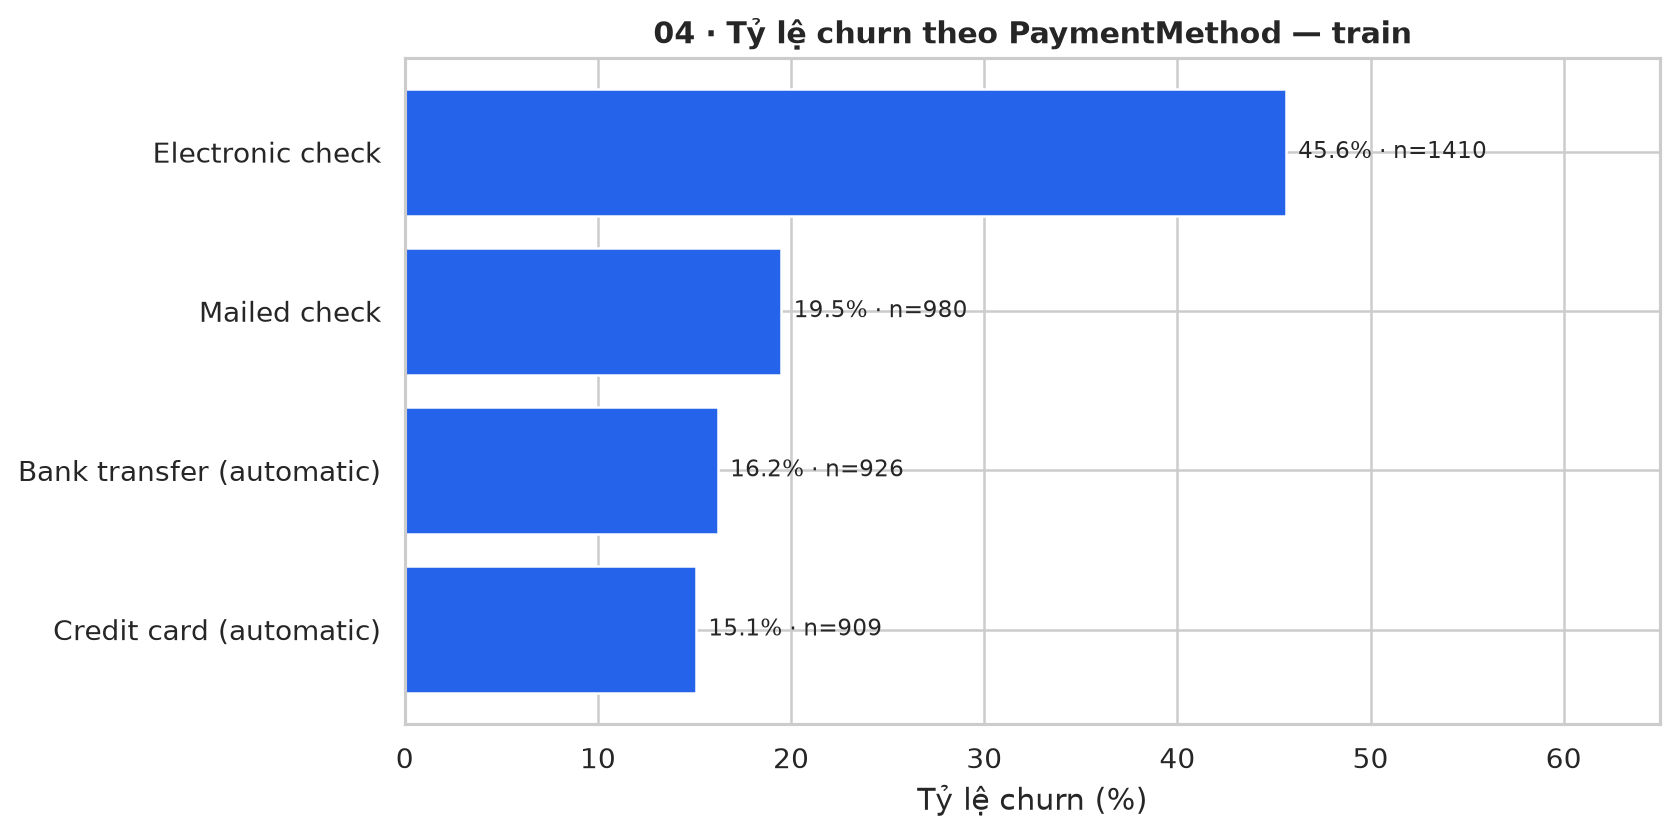

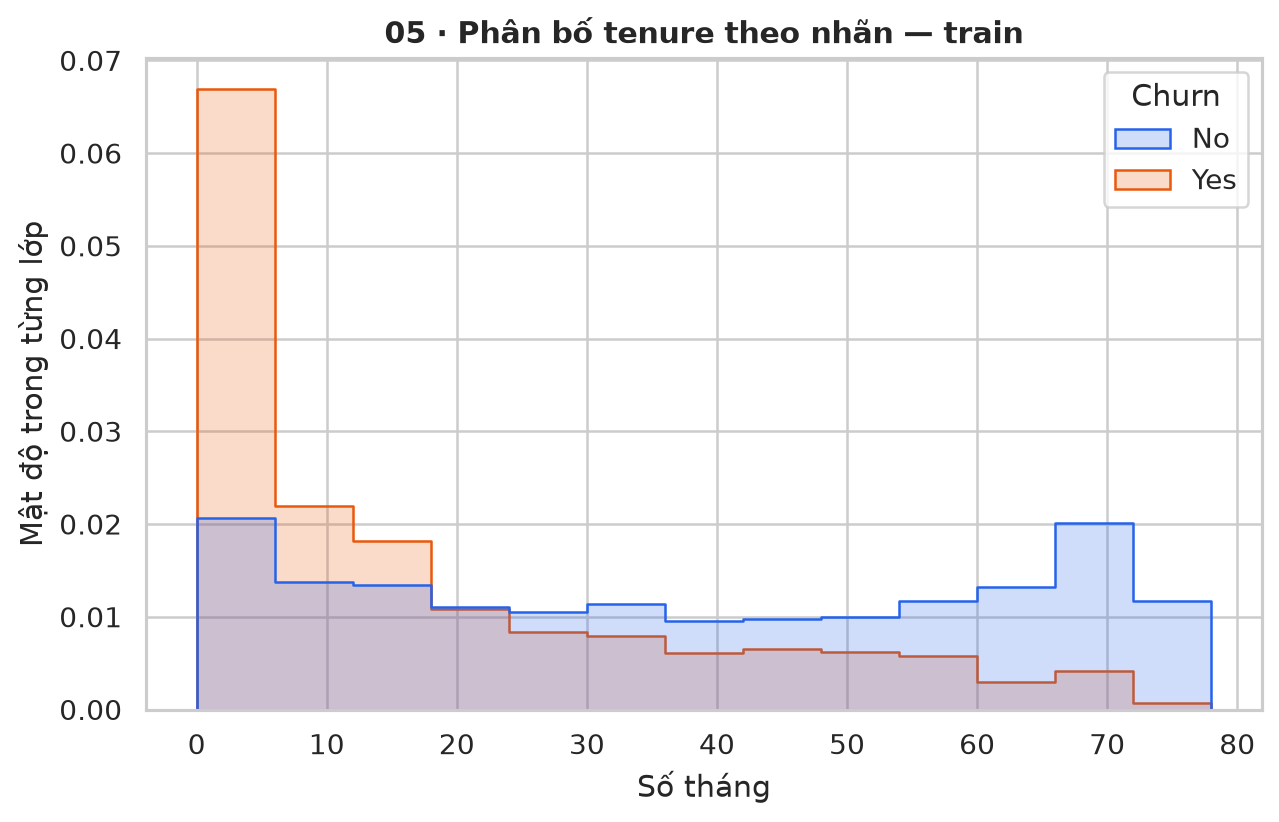

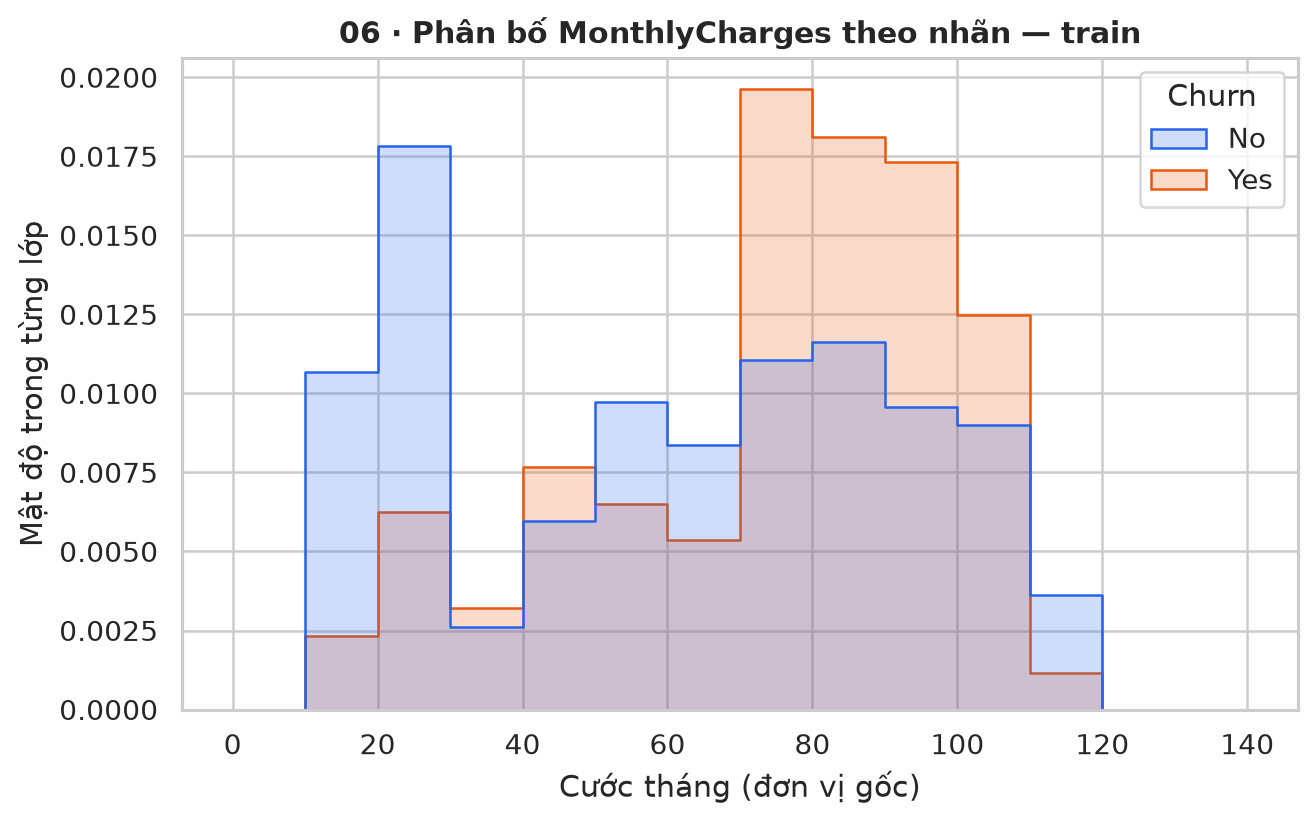

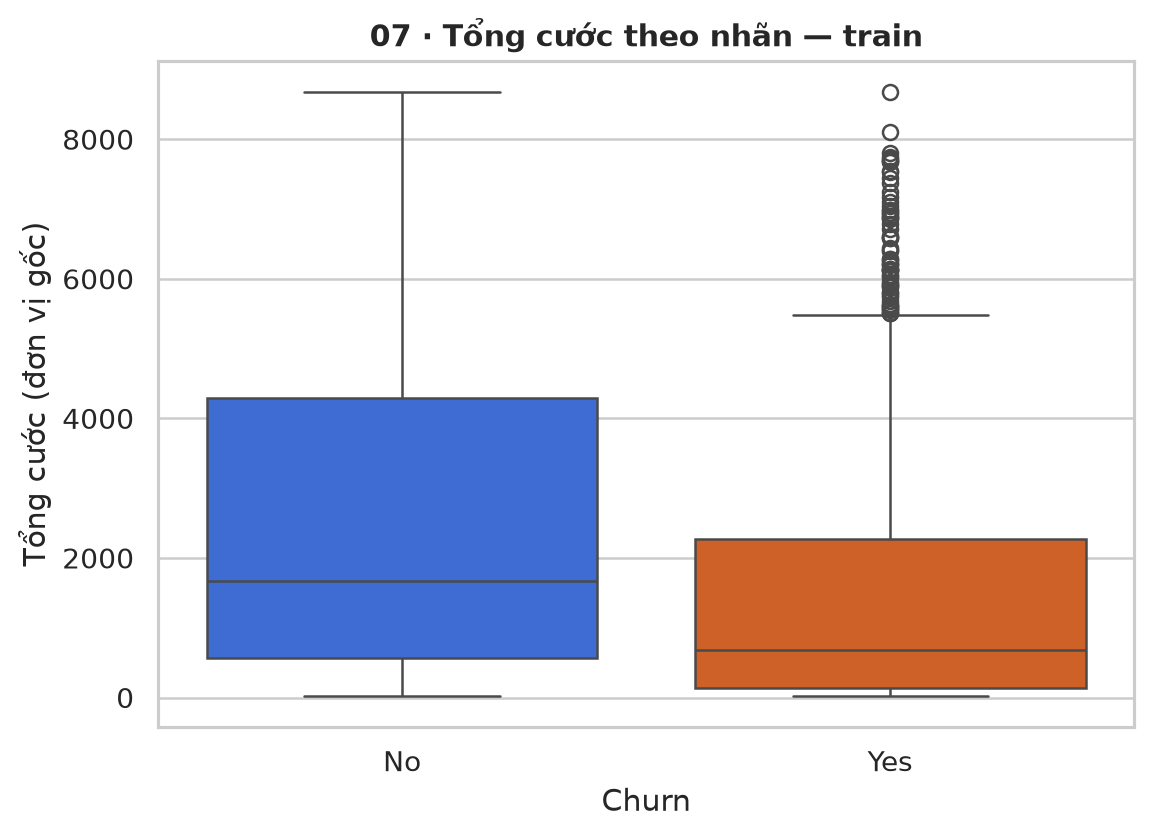

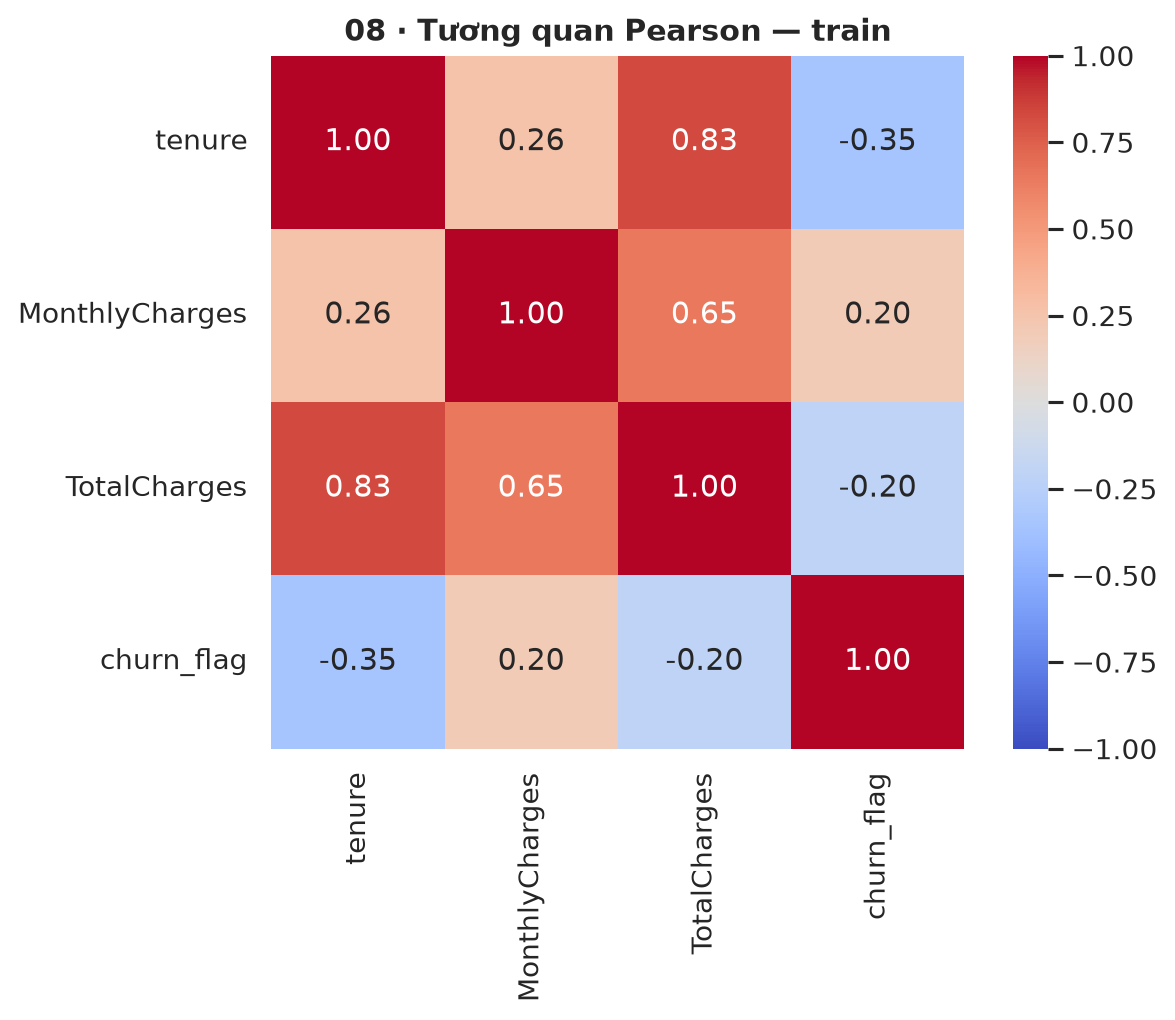

# Nhận xét EDA từ số liệu thật

Phạm vi: train; không dùng validation/test để chọn đặc trưng.

1. Tập train có 4,225 khách; churn 1,121 (26.53%). Accuracy cần so với tỷ lệ lớp đa số 73.47%.

2. Contract: nhóm Month-to-month có tỷ lệ churn 43.08% (n=2326), so với 2.51% (n=1034) ở Two year. Đây là tương quan, không chứng minh nguyên nhân.

3. InternetService: nhóm Fiber optic có tỷ lệ churn 42.32% (n=1843), so với 7.27% (n=908) ở No. Đây là tương quan, không chứng minh nguyên nhân.

4. PaymentMethod: nhóm Electronic check có tỷ lệ churn 45.60% (n=1410), so với 15.07% (n=909) ở Credit card (automatic). Đây là tương quan, không chứng minh nguyên nhân.

5. Median tenure: churn=10.00, không churn=37.00. Các phân bố vẫn chồng lấp; không thể quyết định từ một biến.

6. Median MonthlyCharges: churn=79.75, không churn=64.38. Các phân bố vẫn chồng lấp; không thể quyết định từ một biến.

7. Median TotalCharges: churn=679.30, không churn=1677.85 (đơn vị gốc). Tổng cước còn liên quan thời gian sử dụng, không suy ra tổng cước thấp gây churn. Các điểm ngoài râu hộp chưa đủ bằng chứng là dữ liệu sai nên được giữ lại. Train có 7 TotalCharges thiếu; hình bỏ qua ô thiếu để mô tả, mô hình điền median trong fold/train và không xóa khách.

8. tenure–TotalCharges có tương quan Pearson 0.834; biến liên quan có thể chia sẻ độ quan trọng. Pearson không mô tả đầy đủ quan hệ phi tuyến.

Không suy diễn quan hệ nhân quả từ dữ liệu quan sát. Không thực hiện cắt outlier hoặc xóa đặc trưng theo biểu đồ.


In [3]:
for image in sorted(EDA_DIR.glob('*.png')):
    display(Image(filename=str(image),width=750))
display(Markdown((EDA_DIR/'NHAN_XET_EDA.md').read_text(encoding='utf-8')))

## 4. CV và khóa lựa chọn

Dummy most_frequent; LR: 8 cấu hình; RF: 18 cấu hình × 5 folds. Chọn theo AP trung bình; std phá hòa. Tối đa recall với precision≥0,50 trên validation. Recall≥0,80 là mục tiêu nhóm. Selection record được ghi trước đọc test.

In [4]:
display(pd.read_csv(RUN_DIR/'cv_summary.csv'))
selection=read_json(RUN_DIR/'selection_record.json')
print('Chọn:',selection['selected_model'])
print('Ngưỡng:',selection['selected_threshold'])
print('Khóa trước test:',selection['frozen_at'],'; mở test:',metadata['test_opened_at'])
display(pd.DataFrame([metadata['threshold_records'][metadata['selected_model']]['validation_metrics']]))

,model,candidates,mean_average_precision,std_average_precision,mean_roc_auc,std_roc_auc,mean_accuracy,std_accuracy,mean_precision,std_precision,mean_recall,std_recall,mean_f1,std_f1
0,baseline,1,0.265325,0.000473,0.500000,0.000000,0.734675,0.000473,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,logistic_regression,8,0.667818,0.024414,0.848372,0.010760,0.802604,0.012055,0.649944,0.032800,0.558456,0.023587,0.600258,0.021497
2,random_forest,18,0.672568,0.013939,0.849725,0.011354,0.753136,0.012013,0.523184,0.015239,0.801992,0.017602,0.633022,0.011682


Chọn: random_forest
Ngưỡng: 0.4788031716353531
Khóa trước test: 2026-11-10T09:31:41+07:00 ; mở test: 2026-11-10T09:31:41+07:00


,n,threshold,accuracy,precision_churn,recall_churn,f1_churn,roc_auc,average_precision,tn,fp,fn,tp,flagged_count
0,1409,0.478803,0.735273,0.500832,0.804813,0.617436,0.83815,0.636494,735,300,73,301,601


## 5. Đánh giá và giải thích

Các số test dưới đây chỉ dùng mô tả kết quả. AP khác PR-AUC hình thang. Permutation importance dùng validation; không suy ra nhân quả.

,model,operating_point,n,threshold,accuracy,precision_churn,recall_churn,f1_churn,roc_auc,average_precision,tn,fp,fn,tp,flagged_count
0,baseline,native_most_frequent,1409,0.500000,0.734564,0.000000,0.000000,0.000000,0.500000,0.265436,1035,0,374,0,0
1,logistic_regression,default_0.5,1409,0.500000,0.798439,0.638889,0.553476,0.593123,0.842525,0.628539,918,117,167,207,324
2,logistic_regression,validation_selected,1409,0.243999,0.732434,0.497561,0.818182,0.618807,0.842525,0.628539,726,309,68,306,615
3,random_forest,default_0.5,1409,0.500000,0.752307,0.521891,0.796791,0.630688,0.843451,0.648236,762,273,76,298,571
4,random_forest,validation_selected,1409,0.478803,0.740951,0.507563,0.807487,0.623323,0.843451,0.648236,742,293,72,302,595


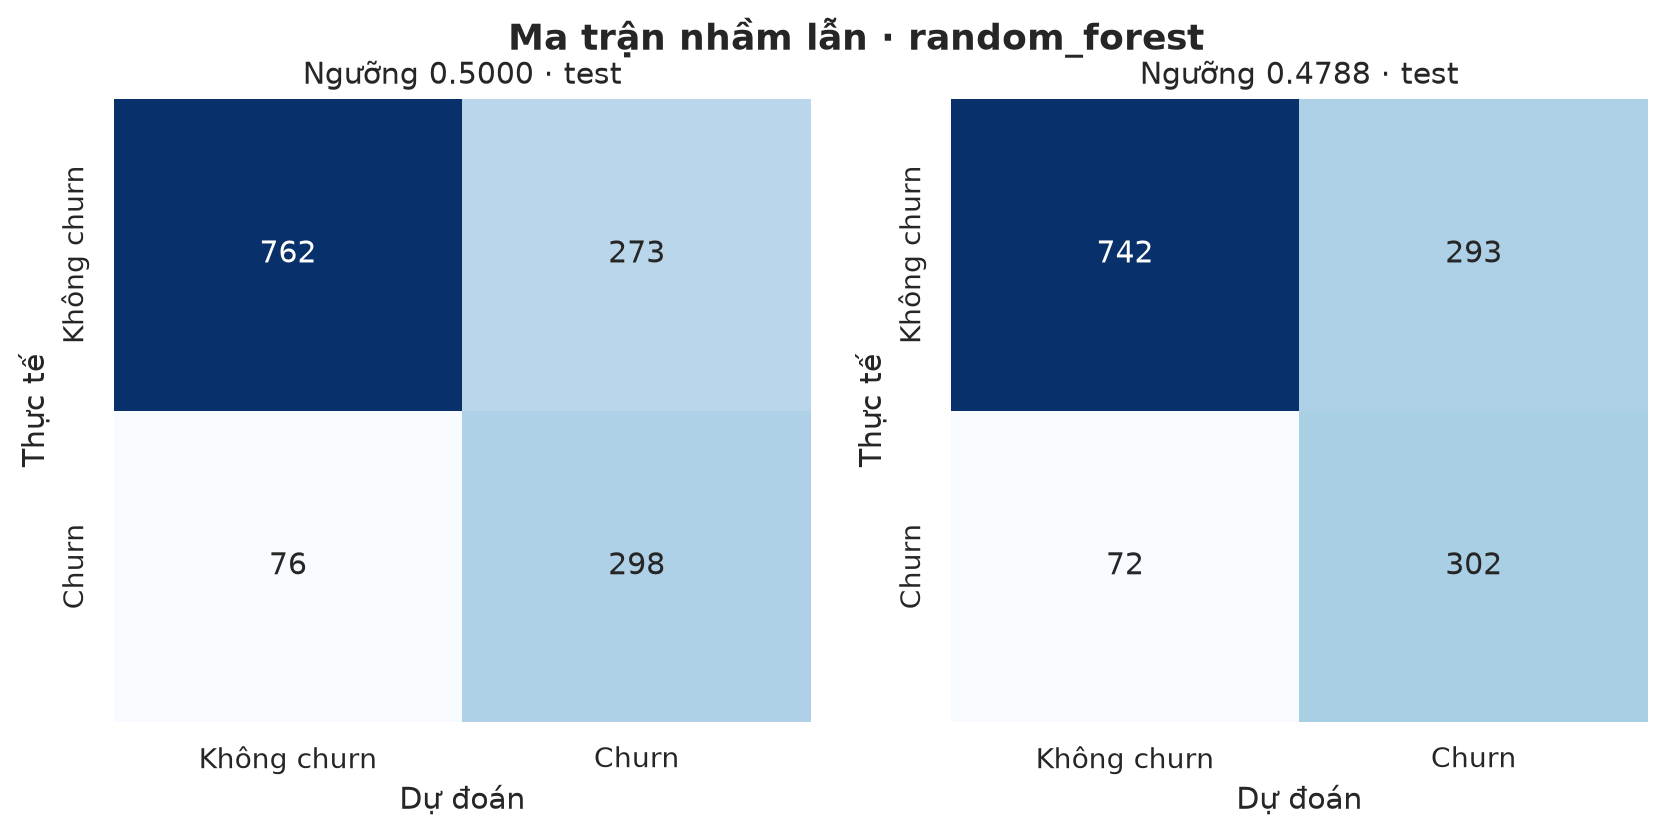

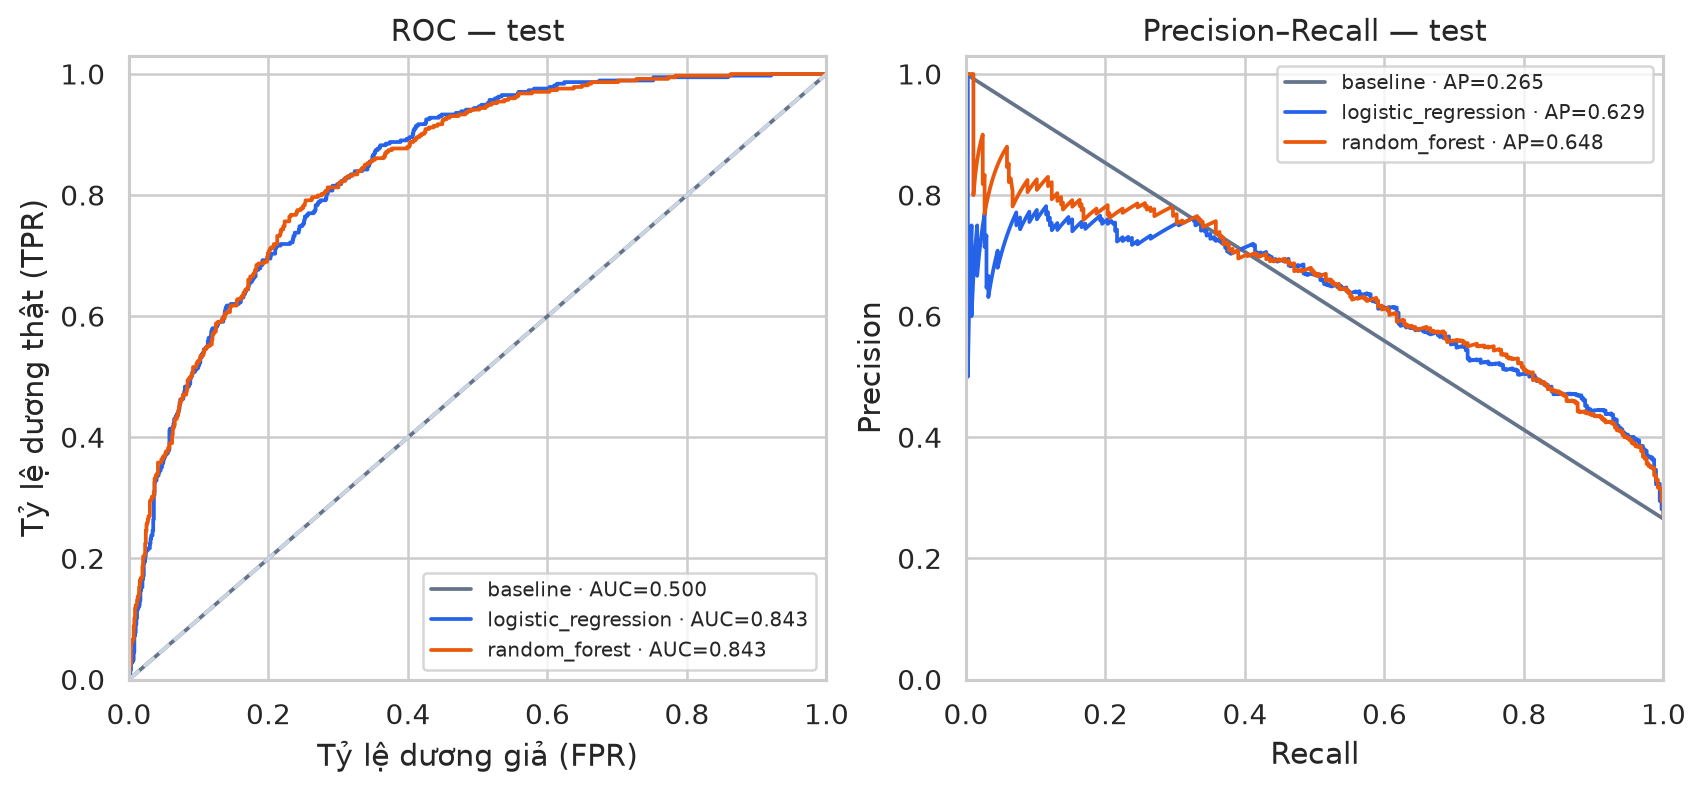

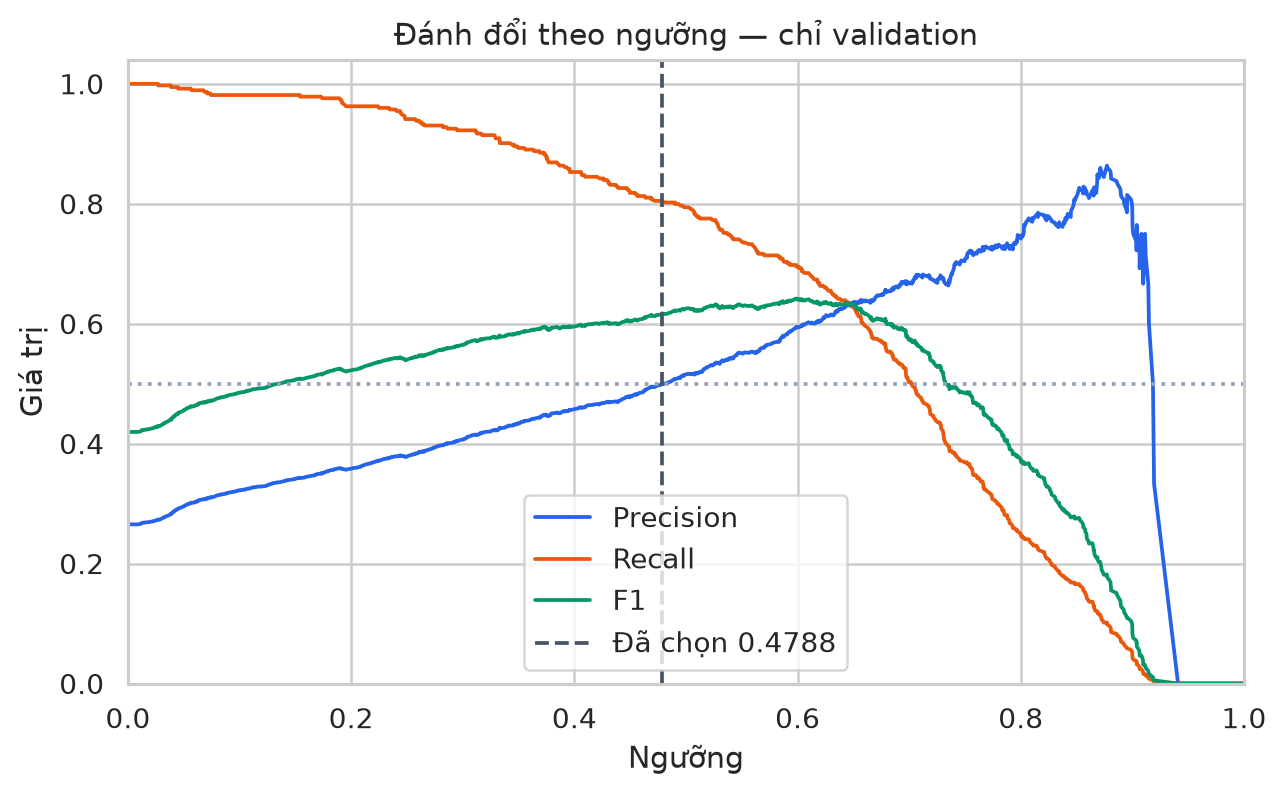

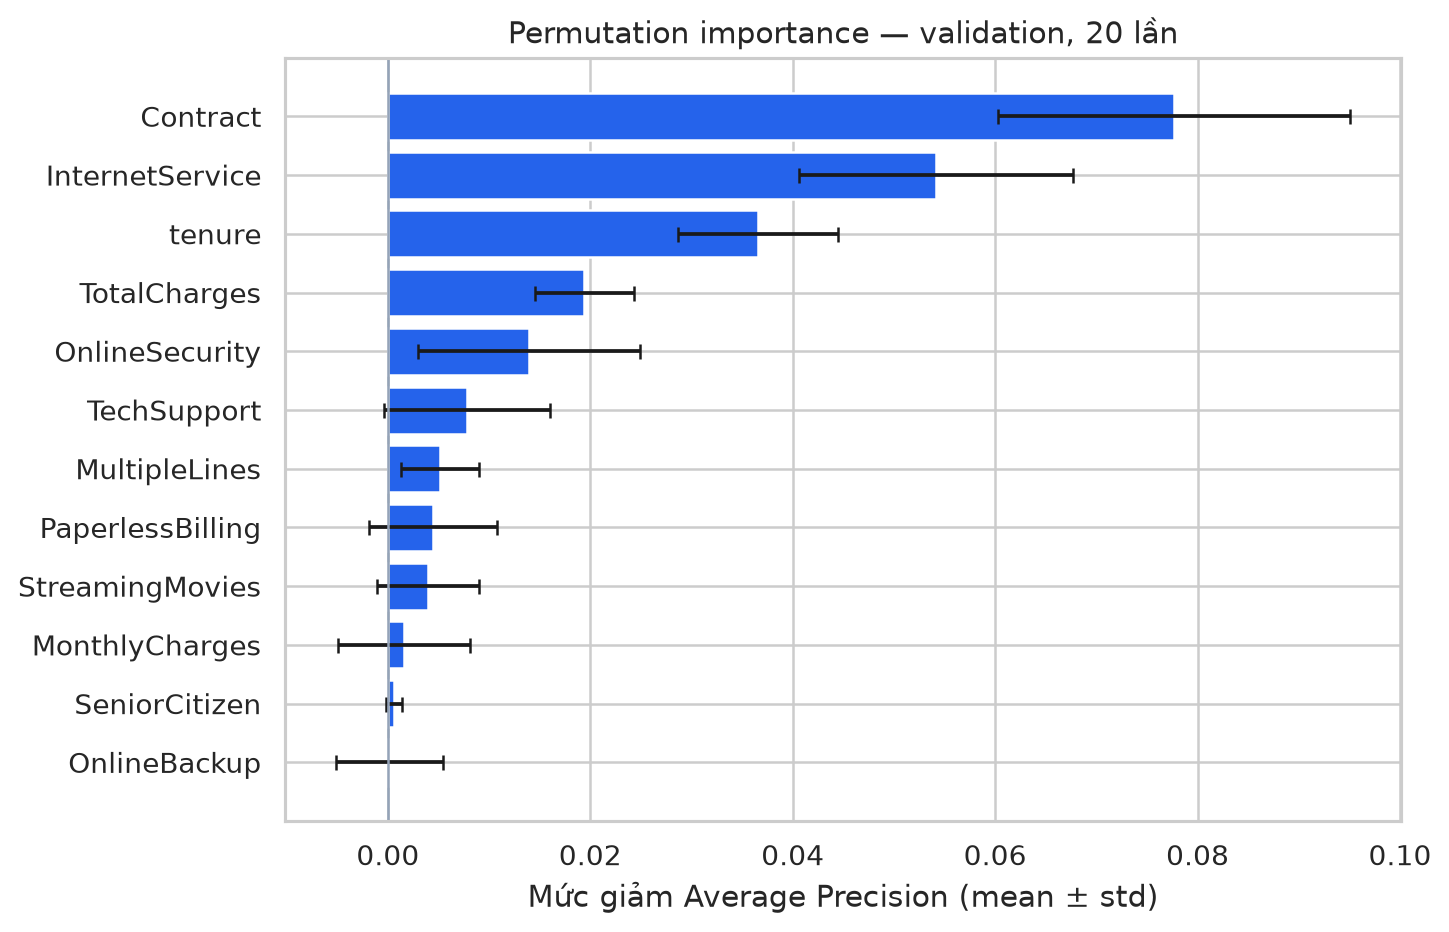

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,y_true,probability,prediction,outcome,distance_from_threshold
0,2545-EBUPK,Female,1,No,No,2,Yes,Yes,Fiber optic,No,...,Yes,Electronic check,84.05,186.05,No,0,0.933254,1,FP,0.454451
1,8739-XNIKG,Female,0,No,No,5,Yes,Yes,Fiber optic,No,...,Yes,Electronic check,84.00,424.75,No,0,0.923160,1,FP,0.444357
2,8161-QYMTT,Male,0,No,No,7,Yes,Yes,Fiber optic,No,...,Yes,Electronic check,94.10,701.30,No,0,0.922616,1,FP,0.443813
3,5804-HYIEZ,Male,0,Yes,Yes,70,Yes,Yes,Fiber optic,Yes,...,Yes,Electronic check,106.05,7554.05,No,0,0.480067,1,FP,0.001264
4,1194-SPVSP,Male,0,No,No,1,Yes,No,No,No internet service,...,No,Bank transfer (automatic),19.65,19.65,No,0,0.481522,1,FP,0.002719
5,8580-QVLOC,Female,1,Yes,Yes,72,Yes,Yes,DSL,Yes,...,No,Credit card (automatic),92.45,6440.25,Yes,1,0.046702,0,FN,0.432101
6,3705-PSNGL,Male,0,No,No,45,Yes,No,No,No internet service,...,Yes,Electronic check,20.40,930.45,Yes,1,0.071823,0,FN,0.406980
7,3400-ESFUW,Male,0,Yes,Yes,55,Yes,No,DSL,Yes,...,No,Bank transfer (automatic),57.55,3046.40,Yes,1,0.078413,0,FN,0.400390
8,4695-VADHF,Male,0,Yes,Yes,18,Yes,No,DSL,No,...,No,Electronic check,57.45,990.85,Yes,1,0.475849,0,FN,0.002954
9,6646-QVXLR,Male,1,Yes,No,62,Yes,Yes,Fiber optic,No,...,Yes,Electronic check,103.75,6383.35,Yes,1,0.475658,0,FN,0.003145


In [5]:
display(pd.read_csv(RUN_DIR/'test_metrics.csv'))
for name in ['evaluation_confusion','evaluation_curves','evaluation_threshold','evaluation_importance']:
    display(Image(filename=str(RUN_DIR/(name+'.png')),width=850))
display(pd.read_csv(RUN_DIR/'error_cases.csv'))

## 6. Giới hạn và nội dung để bảo vệ

Xác suất chưa calibration; chưa có chi phí nghiệp vụ; dữ liệu mẫu không chứng minh tính khái quát ngoài mẫu. Nhóm cần giải thích leakage, split, pipeline, CV, class_weight, threshold, FP/FN, importance và AI usage.

In [6]:
display(Markdown((ROOT/'reports/PHAN_TICH_KET_QUA.md').read_text(encoding='utf-8')))

# Phân tích kết quả thực nghiệm

Run: telco_20261110T093056_0700. Mô hình được chọn bằng train CV: **random_forest**; test không tham gia lựa chọn.

Ngưỡng **0.4788031716** chọn trên validation với precision≥0,50, tối đa recall. Đây là giả định nghiệp vụ, chưa có chi phí giữ chân thực.

Validation: precision=50.08%, recall=80.48%; mục tiêu recall≥80%: đạt.

Test n=1409: AP=0.6482; ROC-AUC=0.8435; accuracy=74.10%; precision=50.76%; recall=80.75%; F1=0.6233.

Test: TP=302, FP=293, FN=72, TN=742. Đánh dấu 595 khách để xem xét; không tự động kết luận phải giữ chân.

FP: 293 khách không churn vẫn bị đánh dấu; có thể làm tăng chi phí liên hệ. FN: 72 khách churn bị bỏ sót; có thể mất cơ hội hỗ trợ. Chưa có dữ liệu can thiệp để suy ra ROI hay hiệu quả giữ chân.

Ba biến có mean permutation importance lớn nhất trên validation: Contract (0.0777 ± 0.0174), InternetService (0.0541 ± 0.0135), tenure (0.0366 ± 0.0079). Đo mức phụ thuộc của mô hình, không phải nguyên nhân churn. Std là độ dao động qua 20 lần hoán vị.

Ví dụ lỗi được lấy tự động: mỗi loại FP/FN gồm 3 lỗi xa ngưỡng nhất và 2 gần ngưỡng nhất, loại trùng; không tuyển chọn thủ công để làm đẹp kết quả.

- 2545-EBUPK: FP, xác suất ước lượng=0.9333, nhãn=No, tenure=2, Contract=Month-to-month, InternetService=Fiber optic. Mẫu này minh họa sai số, không đủ để kết luận nguyên nhân cá nhân.

- 8739-XNIKG: FP, xác suất ước lượng=0.9232, nhãn=No, tenure=5, Contract=Month-to-month, InternetService=Fiber optic. Mẫu này minh họa sai số, không đủ để kết luận nguyên nhân cá nhân.

- 8161-QYMTT: FP, xác suất ước lượng=0.9226, nhãn=No, tenure=7, Contract=Month-to-month, InternetService=Fiber optic. Mẫu này minh họa sai số, không đủ để kết luận nguyên nhân cá nhân.

- 5804-HYIEZ: FP, xác suất ước lượng=0.4801, nhãn=No, tenure=70, Contract=Month-to-month, InternetService=Fiber optic. Mẫu này minh họa sai số, không đủ để kết luận nguyên nhân cá nhân.

- 1194-SPVSP: FP, xác suất ước lượng=0.4815, nhãn=No, tenure=1, Contract=Month-to-month, InternetService=No. Mẫu này minh họa sai số, không đủ để kết luận nguyên nhân cá nhân.

- 8580-QVLOC: FN, xác suất ước lượng=0.0467, nhãn=Yes, tenure=72, Contract=Two year, InternetService=DSL. Mẫu này minh họa sai số, không đủ để kết luận nguyên nhân cá nhân.

- 3705-PSNGL: FN, xác suất ước lượng=0.0718, nhãn=Yes, tenure=45, Contract=One year, InternetService=No. Mẫu này minh họa sai số, không đủ để kết luận nguyên nhân cá nhân.

- 3400-ESFUW: FN, xác suất ước lượng=0.0784, nhãn=Yes, tenure=55, Contract=Two year, InternetService=DSL. Mẫu này minh họa sai số, không đủ để kết luận nguyên nhân cá nhân.

- 4695-VADHF: FN, xác suất ước lượng=0.4758, nhãn=Yes, tenure=18, Contract=Month-to-month, InternetService=DSL. Mẫu này minh họa sai số, không đủ để kết luận nguyên nhân cá nhân.

- 6646-QVXLR: FN, xác suất ước lượng=0.4757, nhãn=Yes, tenure=62, Contract=One year, InternetService=Fiber optic. Mẫu này minh họa sai số, không đủ để kết luận nguyên nhân cá nhân.

## Giới hạn và hướng phát triển

- Dữ liệu mẫu công ty hư cấu; chưa xác minh khả năng áp dụng cho doanh nghiệp Việt Nam.

- Snapshot không có timestamp, không chứng minh dự báo trước một khoảng thời gian cụ thể; ngẫu nhiên stratified không thay thế validation theo thời gian.

- Xác suất chưa hiệu chỉnh calibration. Ngưỡng có thể lệch khi tỷ lệ churn/chi phí thay đổi; cần validation mới.

- Có nhóm nhân khẩu học; bảng subgroup có cỡ mẫu nhưng chưa chứng minh công bằng hoặc tác động thực tế.

- Chênh lệch CV giữa hai mô hình chỉ là ước lượng trên một split/seed; chưa kiểm định khác biệt thống kê.

- Sau khi xem test, không sửa để tối ưu trên test này. Nếu thay thiết kế, cần thí nghiệm mới và tập đánh giá mới phù hợp.

- Đề xuất hỗ trợ nhóm hợp đồng tháng/tenure thấp chỉ là giả thuyết để kiểm tra bằng thử nghiệm can thiệp có kiểm soát.
